# Análise de Risco de Crédito — FIAP

## 01 — Análise Exploratória de Dados (EDA)

**Dimensão 3 da rúbrica — 20 pontos.**

Toda visualização precisa de um parágrafo de interpretação logo abaixo.
Gráfico sem leitura perde metade dos pontos do critério.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

# Semente fixa: use em TODO ponto com aleatoriedade (split, modelos, CV).
RANDOM_STATE = 42

# Caminhos dos dados
RAW = Path("..") / "data" / "raw" / "application_record.csv"
RAW_2 = Path("..") / "data" / "raw" / "credit_record.csv"
PROCESSED = Path("..") / "data" / "processed"
TARGET = "eh_mau_pagador"

pd.set_option("display.max_columns", None)

In [2]:
# ============================================
# CARGA DOS DADOS
# ============================================
# Objetivo: Carregar as bases de dados application_record.csv e credit_record.csv
# Método: pd.read_csv() com fallback para caminhos locais
# Resultado esperado: DataFrames df_app e df_credit carregados
# ============================================

path_app = "application_record.csv" if os.path.exists("application_record.csv") else RAW
path_credit = "credit_record.csv" if os.path.exists("credit_record.csv") else RAW_2

df_app = pd.read_csv(path_app)
df_credit = pd.read_csv(path_credit)

print(f"Base cadastral: {df_app.shape[0]:,} registros x {df_app.shape[1]} colunas")
print(f"Base de crédito: {df_credit.shape[0]:,} registros x {df_credit.shape[1]} colunas")

Base cadastral: 438,557 registros x 18 colunas
Base de crédito: 1,048,575 registros x 3 colunas


### 1. Visão Geral

Dimensões, tipos e primeira impressão do dataset.

#### 1.1 Dimensões, tipos e primeira impressão do dataset ***application_record.csv***.

In [3]:
# ============================================
# ANÁLISE: Visão Geral da Base Cadastral
# ============================================
# Objetivo: Verificar dimensões, tipos de dados e estatísticas descritivas
# Método: df.info() para estrutura e df.describe().T para estatísticas
# Resultado esperado: Identificar variáveis numéricas vs categóricas, nulos e outliers
# ============================================

print("=== BASE CADASTRAL (application_record.csv) ===")
df_app.info()
print()
df_app.describe().T

=== BASE CADASTRAL (application_record.csv) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  object 
 2   FLAG_OWN_CAR         438557 non-null  object 
 3   FLAG_OWN_REALTY      438557 non-null  object 
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  object 
 7   NAME_EDUCATION_TYPE  438557 non-null  object 
 8   NAME_FAMILY_STATUS   438557 non-null  object 
 9   NAME_HOUSING_TYPE    438557 non-null  object 
 10  DAYS_BIRTH           438557 non-null  int64  
 11  DAYS_EMPLOYED        438557 non-null  int64  
 12  FLAG_MOBIL           438557 non-null  int64  
 13  FLAG_WORK_PHONE      438557 non-null  int64  
 14  FLAG_PHONE          

,count,mean,std,min,25%,50%,75%,max
ID,438557.0,6.022176e+06,571637.023257,5008804.0,5609375.0,6047745.0,6456971.0,7999952.0
CNT_CHILDREN,438557.0,4.273903e-01,0.724882,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,438557.0,1.875243e+05,110086.853066,26100.0,121500.0,160780.5,225000.0,6750000.0
DAYS_BIRTH,438557.0,-1.599790e+04,4185.030007,-25201.0,-19483.0,-15630.0,-12514.0,-7489.0
DAYS_EMPLOYED,438557.0,6.056368e+04,138767.799647,-17531.0,-3103.0,-1467.0,-371.0,365243.0
FLAG_MOBIL,438557.0,1.000000e+00,0.000000,1.0,1.0,1.0,1.0,1.0
FLAG_WORK_PHONE,438557.0,2.061328e-01,0.404527,0.0,0.0,0.0,0.0,1.0
FLAG_PHONE,438557.0,2.877710e-01,0.452724,0.0,0.0,0.0,1.0,1.0
FLAG_EMAIL,438557.0,1.082071e-01,0.310642,0.0,0.0,0.0,0.0,1.0
CNT_FAM_MEMBERS,438557.0,2.194465e+00,0.897207,1.0,2.0,2.0,3.0,20.0


ID (Identificador do Cliente)

CNT_CHILDREN (Quantidade de Filhos)

Dados: Média de 0,43 e mediana 0; pelo menos 75% da base não tem filhos. Máximo de 19.

AMT_INCOME_TOTAL (Renda Anual)

Dados: Média de 187,5k, mediana de 160,8k e teto de 6,75M, demonstrando forte assimetria à direita.

DAYS_BIRTH (Idade)

Dados: Varia de -25.201 (69 anos) a -7.489 (20 anos), com média de ~43,8 anos. Valores negativos indicam dias antes da aplicação.

DAYS_EMPLOYED (Tempo de Emprego)

Dados: Mediana de -1.467 dias, mínimo de -17.531 e presença do valor sentinela positivo 365.243.

FLAG_MOBIL (Celular)

Dados: Constante (100% da base possui celular; variância zero).

FLAG_WORK_PHONE (Telefone Comercial)

Dados: Presente em ~21% da base.

FLAG_PHONE (Telefone Residencial)

Dados: Presente em ~29% da base.

FLAG_EMAIL (E-mail)

Dados: Apenas ~11% dos clientes informaram.

CNT_FAM_MEMBERS (Tamanho da Família)

**Interpretação:**

A base cadastral possui **438.557 registros** e **18 colunas**, com tipos variados (int64, float64 e object). A coluna `OCCUPATION_TYPE` é a única com valores nulos (134.203 registros, ~30%). As variáveis numéricas mostram:

- `AMT_INCOME_TOTAL`: média de ~187.524, desvio padrão de ~110.086 e valor máximo de 6.750.000 — indicando forte assimetria e presença de outliers de alta renda.
- `DAYS_BIRTH`: média de -15.997 dias (~43,8 anos), variando de -25.201 dias (~69 anos) a -7.489 dias (~20 anos).
- `DAYS_EMPLOYED`: média de ~60.564 dias, com valor máximo de 365.243 — um código técnico para inativos/aposentados.
- `CNT_CHILDREN` e `CNT_FAM_MEMBERS`: valores máximos de 19 e 20, indicando casos extremos ou potenciais erros de cadastro.

#### 1.2 Dimensões, tipos e primeira impressão do dataset ***credit_record.csv***

In [4]:
# ============================================
# ANÁLISE: Visão Geral da Base de Crédito
# ============================================
# Objetivo: Verificar dimensões, tipos de dados e estatísticas descritivas
# Método: df.info() para estrutura e df.describe().T para estatísticas
# Resultado esperado: Identificar a estrutura do histórico mensal de crédito
# ============================================

print("=== BASE DE CRÉDITO (credit_record.csv) ===")
df_credit.info()
print()
df_credit.describe().T

=== BASE DE CRÉDITO (credit_record.csv) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 3 columns):
 #   Column          Non-Null Count    Dtype 
---  ------          --------------    ----- 
 0   ID              1048575 non-null  int64 
 1   MONTHS_BALANCE  1048575 non-null  int64 
 2   STATUS          1048575 non-null  object
dtypes: int64(2), object(1)
memory usage: 24.0+ MB



,count,mean,std,min,25%,50%,75%,max
ID,1048575.0,5.068286e+06,46150.578505,5001711.0,5023644.0,5062104.0,5113856.0,5150487.0
MONTHS_BALANCE,1048575.0,-1.913700e+01,14.023498,-60.0,-29.0,-17.0,-7.0,0.0


**Interpretação:**

A base de crédito possui **1.048.575 registros** e **3 colunas** (ID, MONTHS_BALANCE, STATUS). Cada cliente possui múltiplas linhas representando seu histórico mensal de pagamento. A coluna `STATUS` é categórica (object) e contém os valores: 0, 1, 2, 3, 4, 5, C e X. A variável `MONTHS_BALANCE` varia de -60 a 0, onde 0 representa o mês atual e valores negativos representam meses anteriores.

In [5]:
# ============================================
# ANÁLISE: Valores Únicos da Coluna STATUS
# ============================================
# Objetivo: Identificar todas as categorias presentes na coluna STATUS
# Método: df.unique() e df.nunique()
# Resultado esperado: Lista completa de categorias e contagem
# ============================================

print("Valores únicos:", df_credit["STATUS"].unique().tolist())
print("Nº de categorias:", df_credit["STATUS"].nunique())

Valores únicos: ['X', '0', 'C', '1', '2', '3', '4', '5']
Nº de categorias: 8


**Interpretação:**

A coluna `STATUS` possui **8 categorias** distintas, sem valores nulos:

| Código | Significado |
|--------|-------------|
| `X` | Sem empréstimo no mês |
| `C` | Quitado no mês |
| `0` | 1 a 29 dias de atraso |
| `1` | 30 a 59 dias |
| `2` | 60 a 89 dias |
| `3` | 90 a 119 dias |
| `4` | 120 a 149 dias |
| `5` | >150 dias — dívida incobrável (baixa contábil) |

## 2. Distribuição das variáveis



### 2.1 Dataset ***application_record.csv***

#### 2.1.1 Quantidade de Crianças

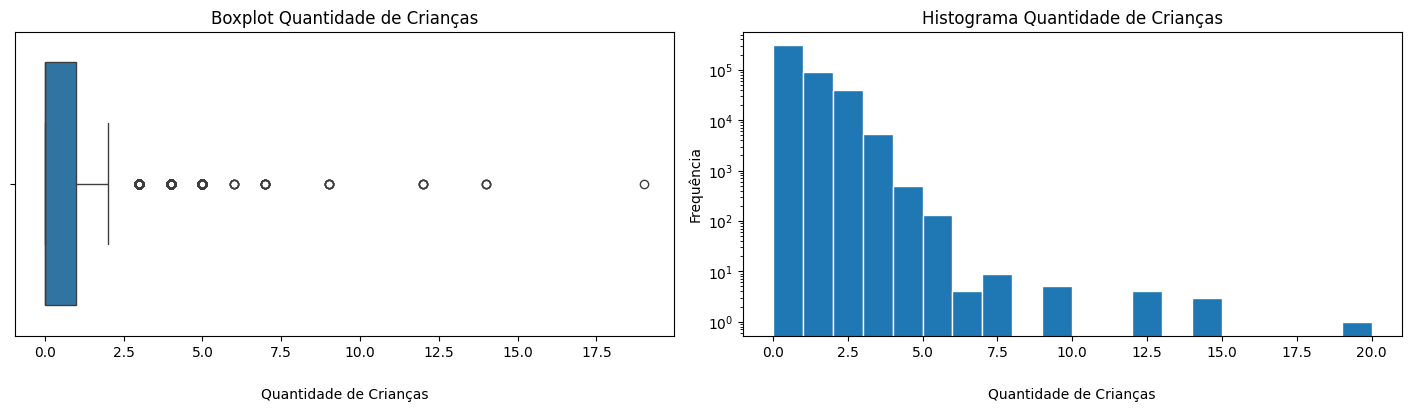

In [6]:
# ============================================
# ANÁLISE: Distribuição da Quantidade de Crianças
# ============================================
# Objetivo: Verificar a distribuição e identificar outliers na variável CNT_CHILDREN
# Método: Boxplot + Histograma (escala log)
# Resultado esperado: Maioria com 0-1 filhos, cauda longa com casos extremos
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)

sns.set(style="whitegrid")
sns.boxplot(x="CNT_CHILDREN", data=df_app, ax=axes[0])
axes[0].set_xlabel("Quantidade de Crianças", labelpad=20)
axes[0].set_title("Boxplot Quantidade de Crianças")

axes[1].hist(df_app["CNT_CHILDREN"], bins=range(0, 21))
axes[1].set_ylabel("Frequência")
axes[1].set_xlabel("Quantidade de Crianças", labelpad=20)
axes[1].set_title("Histograma Quantidade de Crianças")
axes[1].set_yscale("log")  # Escala Logarítmica para melhor visualização
plt.show()

**Interpretação:**

**Boxplot:** A caixa (IQR) está comprimida próxima de zero; pelo menos 75% dos clientes têm 0 ou 1 filho e o limite superior (bigode) vai até ~2. Há forte assimetria à direita com múltiplos pontos discrepantes, alcançando o caso extremo de 19 filhos.

**Histograma:** A frequência concentra-se massivamente em 0 (~100 mil registros), seguida por um decaimento abrupto conforme o número de dependentes sobe. A distribuição é assimétrica com cauda estendida até 19–20 filhos, atingindo frequência unitária nos extremos.

**Diagnóstico Consolidado:** ~70% da base não tem filhos e ~90% possui no máximo 1 dependente. Casos extremos (10 a 19 filhos) representam menos de 1% da amostra e devem ser tratados como outliers ou inconsistências cadastrais.

#### 2.1.2 Ganhos Anuais

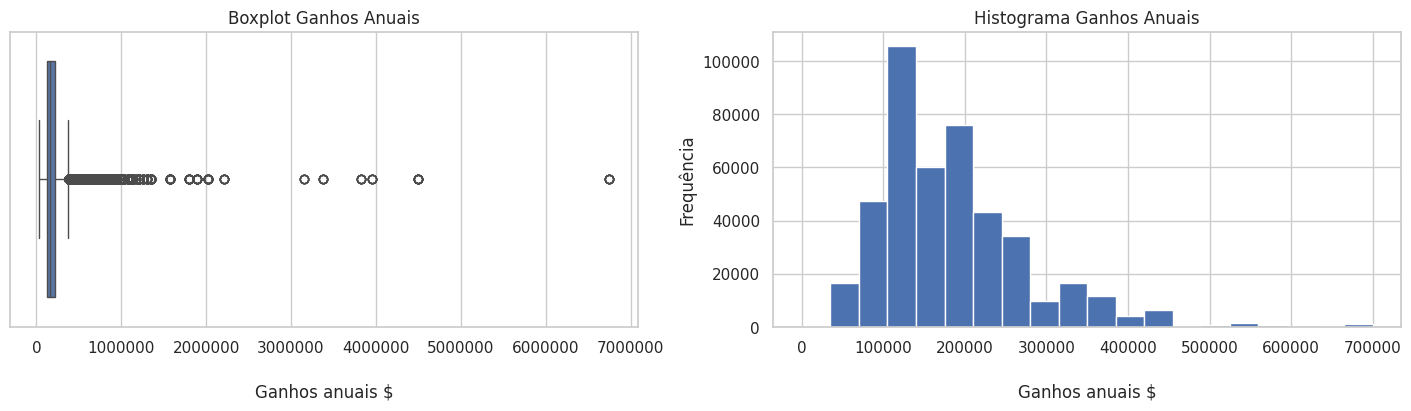

In [7]:
# ============================================
# ANÁLISE: Distribuição dos Ganhos Anuais
# ============================================
# Objetivo: Verificar a assimetria e presença de outliers na variável AMT_INCOME_TOTAL
# Método: Boxplot + Histograma
# Resultado esperado: Forte assimetria à direita, outliers de alta renda
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)

sns.set(style="whitegrid")
sns.boxplot(x="AMT_INCOME_TOTAL", data=df_app, ax=axes[0])
axes[0].set_xlabel("Ganhos anuais $", labelpad=20)
axes[0].ticklabel_format(axis="x", style="plain", useOffset=False)
axes[0].set_title("Boxplot Ganhos Anuais")

axes[1].hist(df_app["AMT_INCOME_TOTAL"], bins=20, range=(0, 700000))
axes[1].set_ylabel("Frequência")
axes[1].set_xlabel("Ganhos anuais $", labelpad=20)
axes[1].set_title("Histograma Ganhos Anuais")
plt.show()

**Interpretação:**

**Boxplot:** A caixa (IQR) concentra-se à esquerda (Q1 ~100k, Mediana ~150k e Q3 ~250k) e o bigode superior é curto, indicando predominância de rendas baixas a médias. Há múltiplos pontos extremos à direita, alcançando rendas de até ~7M (dezenas de vezes acima da mediana).

**Histograma:** A distribuição é unimodal com forte assimetria positiva (à direita), tendo pico entre ~100k e ~150k. A concentração maciça está entre ~50k e ~300k; valores acima de ~400k tornam-se progressivamente raros na base.

**Assimetria:** A mediana (~150k) está sensivelmente inferior à média, puxada pela cauda longa de altos rendimentos. Outliers extremos (> 1M) representam uma fração mínima, mas distorcem métricas paramétricas.

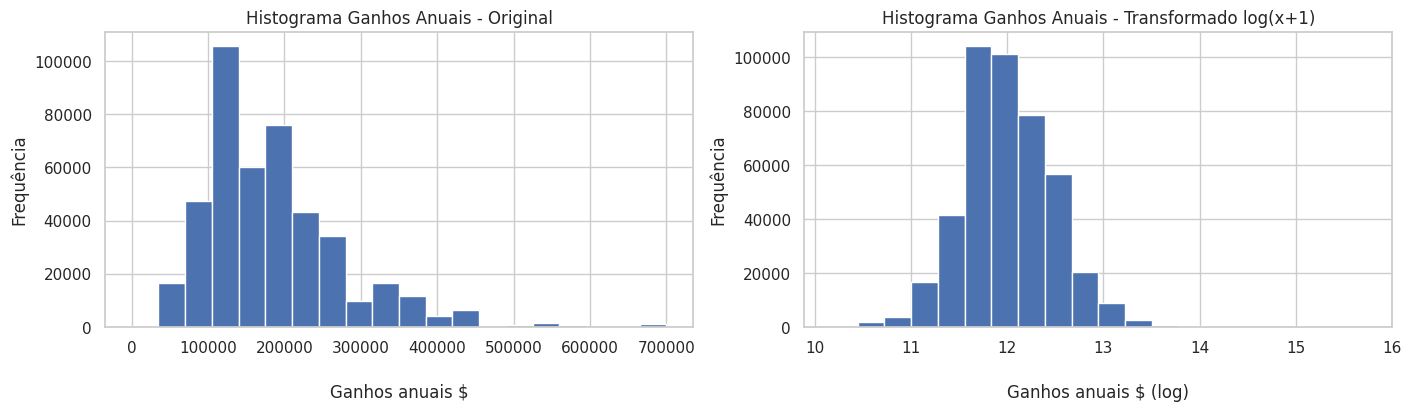

In [8]:
# ============================================
# ANÁLISE: Transformação Logarítmica da Renda
# ============================================
# Objetivo: Verificar se a transformação log1p reduz a assimetria
# Método: np.log1p() para criar AMT_INCOME_TOTAL_LOG
# Resultado esperado: Distribuição mais simétrica, próxima à normal
# ============================================

df_app["AMT_INCOME_TOTAL_LOG"] = np.log1p(df_app["AMT_INCOME_TOTAL"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)

axes[0].hist(df_app["AMT_INCOME_TOTAL"], bins=20, range=(0, 700000))
axes[0].set_ylabel("Frequência")
axes[0].set_xlabel("Ganhos anuais $", labelpad=20)
axes[0].set_title("Histograma Ganhos Anuais - Original")

axes[1].hist(df_app["AMT_INCOME_TOTAL_LOG"], bins=20)
axes[1].set_ylabel("Frequência")
axes[1].set_xlabel("Ganhos anuais $ (log)", labelpad=20)
axes[1].set_title("Histograma Ganhos Anuais - Transformado log(x+1)")
plt.show()

**Interpretação:**

**Histograma Original:** A grande maioria dos clientes está concentrada na faixa de menor renda (entre R$ 100.000 e R$ 250.000 anuais), enquanto a cauda do gráfico se estende longamente para a direita, alcançando valores extremos de até R$ 6.750.000 (outliers legítimos de alta renda).

**Histograma Transformado (log1p):** Ao aplicarmos a transformação logarítmica (np.log1p), comprimimos os valores de alta renda e expandimos a variação nas faixas de menor renda. O resultado é um gráfico em formato de sino, muito mais simétrico e centralizado.

**Vantagens:**
- Redução do impacto de outliers: Os valores multimilionários que antes distorciam a escala agora se alinham perfeitamente ao final da distribuição normalizada.
- Melhor desempenho do modelo: Variáveis com distribuição normalizada facilitam a convergência e a estabilidade matemática de modelos paramétricos.

#### 2.1.3 Tempo Empregado

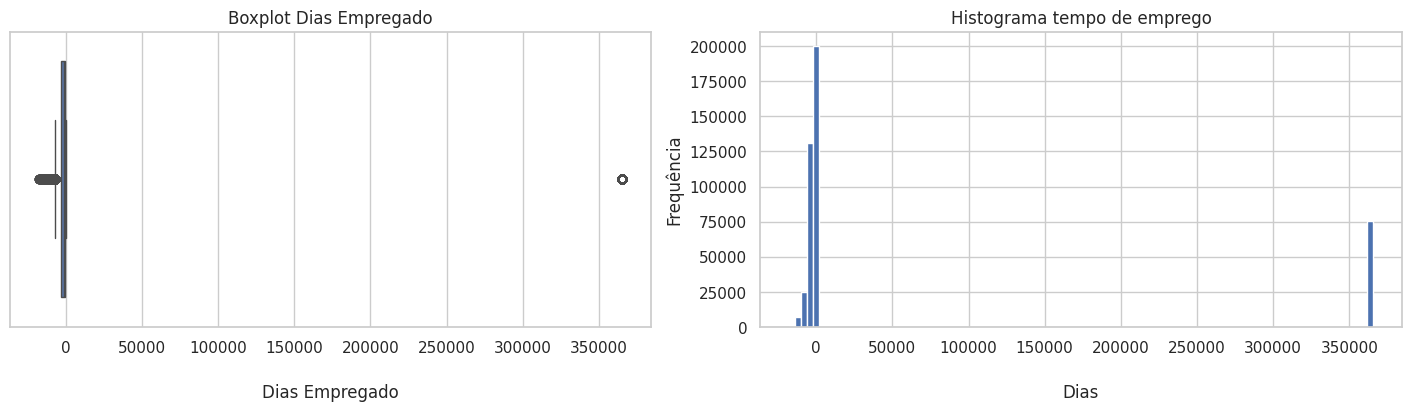

In [9]:
# ============================================
# ANÁLISE: Distribuição do Tempo de Emprego
# ============================================
# Objetivo: Verificar a distribuição e identificar o valor sentinela 365243
# Método: Boxplot + Histograma
# Resultado esperado: Pico anômalo em 365243 (inativos/aposentados)
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)

sns.set(style="whitegrid")
sns.boxplot(x="DAYS_EMPLOYED", data=df_app, ax=axes[0])
axes[0].set_xlabel("Dias Empregado", labelpad=20)
axes[0].ticklabel_format(axis="x", style="plain", useOffset=False)
axes[0].set_title("Boxplot Dias Empregado")

axes[1].hist(df_app["DAYS_EMPLOYED"], bins=100)
axes[1].set_ylabel("Frequência")
axes[1].set_xlabel("Dias", labelpad=20)
axes[1].set_title("Histograma tempo de emprego")
plt.show()

**Interpretação:**

**Boxplot:** A caixa interquartil (IQR) e os limites comuns ficam invisíveis e achatados junto ao zero. A escala visual é dominada pelo valor isolado na extrema direita (~365.243 dias, equivalente a mais de 1.000 anos de trabalho).

**Histograma (Bimodalidade Artificial):** Há um pico expressivo de alta frequência próximo a zero, representando os clientes com tempo de emprego real registrado. Uma barra vertical isolada exatamente em 365.243 dias concentra cerca de 17% de toda a base de dados.

**Conclusão:** O valor 365.243 não reflete tempo trabalhado; é um placeholder (valor sentinela) para identificar a ausência de vínculo empregatício formal (pensionistas ou aposentados). A variável DAYS_EMPLOYED não pode entrar diretamente no modelo sem tratamento.

In [10]:
# ============================================
# ANÁLISE: Verificação do Valor Sentinela 365243
# ============================================
# Objetivo: Confirmar que o valor 365243 representa inativos/aposentados
# Método: Filtrar registros com DAYS_EMPLOYED == 365243 e verificar NAME_INCOME_TYPE
# Resultado esperado: Todos os registros com 365243 devem ter NAME_INCOME_TYPE = Pensioner
# ============================================

ocupacao_outlier = df_app[df_app["DAYS_EMPLOYED"] == 365243]["NAME_INCOME_TYPE"].unique().tolist()
percentagem_outlier = df_app[df_app["DAYS_EMPLOYED"] == 365243]["ID"].count() / df_app["ID"].count() * 100

print(f"Ocupação Cliente com 365243 de tempo de emprego: {ocupacao_outlier}")
print(f"Percentagem Clientes com 365243 de tempo de emprego: {percentagem_outlier:.2f} %")

Ocupação Cliente com 365243 de tempo de emprego: ['Pensioner']
Percentagem Clientes com 365243 de tempo de emprego: 17.18 %


**Interpretação:**

O valor 365.243 aparece em **75.329 registros (~17,2% da base)**, e todos esses clientes possuem `NAME_INCOME_TYPE = Pensioner`. Isso confirma que o valor é um **código técnico do sistema** para indicar clientes inativos (aposentados ou desempregados), não 1.000 anos de emprego.

**Decisão:** Substituir o valor sentinela por NaN, deixando explícito que a informação é ausente.
Criar a flag IS_EMPLOYED_MISSING, que preserva o sinal de que aquele cliente pertence ao grupo sem emprego formal — um padrão que pode ser preditivo para risco de crédito.

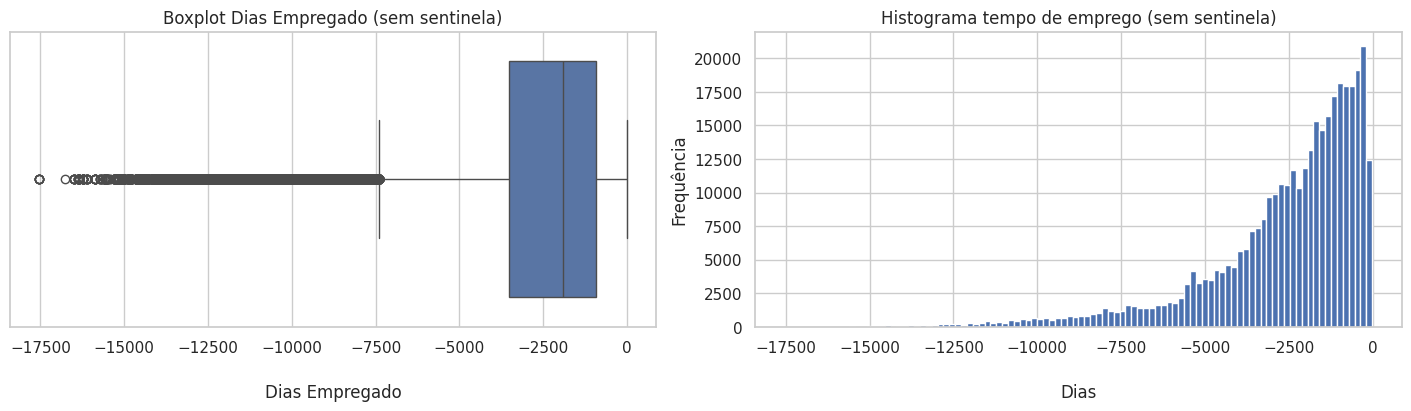

In [11]:
# ============================================
# ANÁLISE: Distribuição do Tempo de Emprego (sem valor sentinela)
# ============================================
# Objetivo: Verificar a distribuição real do tempo de emprego, excluindo o valor 365243
# Método: Boxplot + Histograma filtrando DAYS_EMPLOYED != 365243
# Resultado esperado: Distribuição unimodal com pico próximo a zero
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)

sns.set(style="whitegrid")
sns.boxplot(x="DAYS_EMPLOYED", data=df_app[df_app["DAYS_EMPLOYED"] != 365243], ax=axes[0])
axes[0].set_xlabel("Dias Empregado", labelpad=20)
axes[0].ticklabel_format(axis="x", style="plain", useOffset=False)
axes[0].set_title("Boxplot Dias Empregado (sem sentinela)")

axes[1].hist(df_app[df_app["DAYS_EMPLOYED"] != 365243]["DAYS_EMPLOYED"], bins=100)
axes[1].set_ylabel("Frequência")
axes[1].set_xlabel("Dias", labelpad=20)
axes[1].set_title("Histograma tempo de emprego (sem sentinela)")
plt.show()

**Interpretação:**

**Boxplot (Distribuição e Dispersão):** A caixa situa-se próxima de zero, indicando que a maioria dos clientes tem pouco tempo de casa: o terceiro quartil (Q3) fica em torno de -800 dias (~2 anos) e a mediana em cerca de -2.000 dias (~5,5 anos). O bigode estende-se até ~-7.500 dias (~20 anos). À esquerda no eixo, destacam-se pontos discrepantes que alcançam até -17.500 dias (~48 anos de carteira assinada) — casos raros de colaboradores com décadas de permanência.

**Histograma (Frequência e Assimetria):** A distribuição é unimodal, com concentração maciça próxima de zero (~20.000 registros), decaindo progressivamente à medida que os valores se tornam mais negativos. A cauda longa estende-se em direção aos valores mais antigos, confirmando visualmente a assimetria: o volume de recém-contratados supera amplamente o de profissionais consolidados.

**Conclusão:** Vínculos curtos são o padrão da carteira; longa estabilidade no emprego é a exceção.

#### 2.1.4 Idade

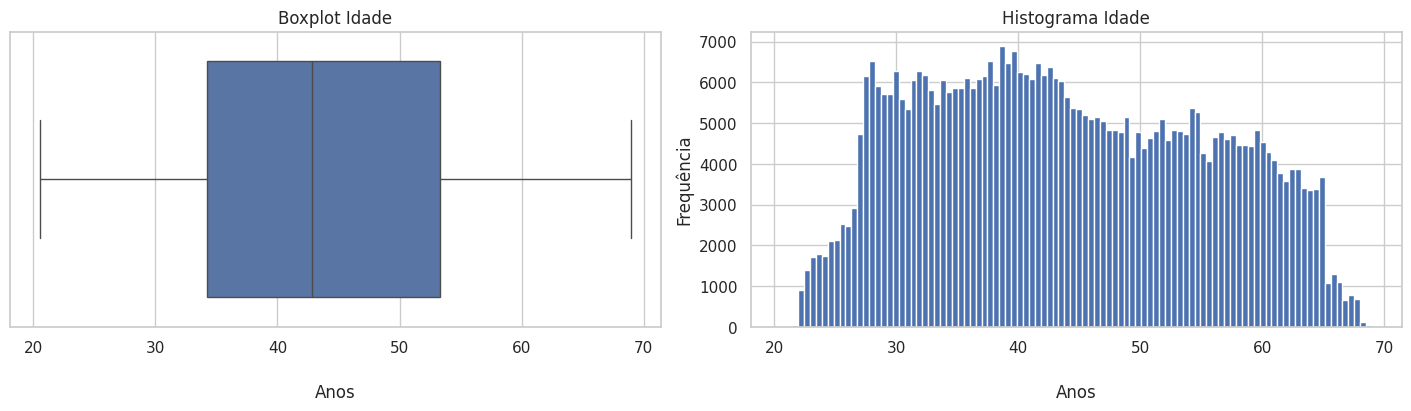

In [12]:
# ============================================
# ANÁLISE: Distribuição da Idade
# ============================================
# Objetivo: Verificar a distribuição da idade dos clientes
# Método: Boxplot + Histograma (convertendo dias para anos)
# Resultado esperado: Distribuição equilibrada, sem outliers
# ============================================

df_app["idade_anos"] = df_app["DAYS_BIRTH"] / 365.25 * -1

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)

sns.set(style="whitegrid")
sns.boxplot(x="idade_anos", data=df_app, ax=axes[0])
axes[0].set_xlabel("Anos", labelpad=20)
axes[0].ticklabel_format(axis="x", style="plain", useOffset=False)
axes[0].set_title("Boxplot Idade")

axes[1].hist(df_app["idade_anos"], bins=100)
axes[1].set_ylabel("Frequência")
axes[1].set_xlabel("Anos", labelpad=20)
axes[1].set_title("Histograma Idade")

df_app = df_app.drop("idade_anos", axis=1)
plt.show()

**Interpretação:**

**Boxplot (Distribuição e Dispersão):** A dispersão é equilibrada: a caixa interquartil (IQR) é ampla e bem distribuída, evidenciando que metade da base (50%) situa-se entre 35 anos (Q1) e 52 anos (Q3), com mediana em ~43 anos. Os limites normais (bigodes) cobrem de ~21 a ~68 anos de forma contínua, sem pontos discrepantes ou caixas achatadas — ao contrário de variáveis como renda ou tempo de emprego.

**Histograma (Frequência e Formato):** A distribuição é bem-comportada: formato aproximadamente simétrico e contínuo, com pico concentrado entre 38 e 42 anos (~6.500 a 7.000 clientes por faixa) e declínio suave para ambas as extremidades. Apresenta uma discreta cauda à direita (volume ligeiramente mais estendido após os 55 anos do que antes dos 25), sem qualquer barra anômala ou valor isolado.

**Conclusão:** A carteira é composta predominantemente por adultos em idade produtiva e de estabilidade profissional (30 a 55 anos).

#### 2.1.5 Tamanho da Família

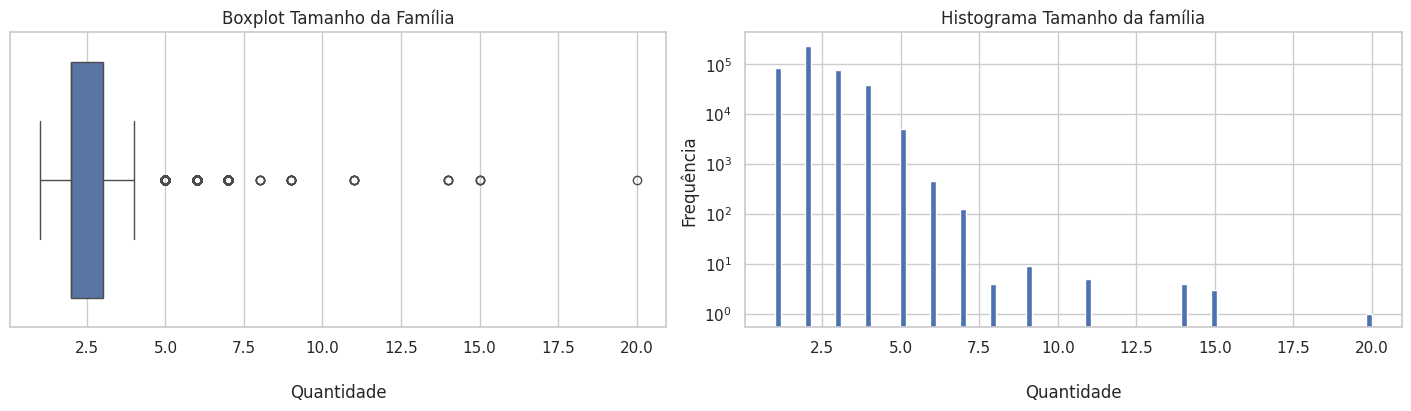

In [13]:
# ============================================
# ANÁLISE: Distribuição do Tamanho da Família
# ============================================
# Objetivo: Verificar a distribuição do número de membros da família
# Método: Boxplot + Histograma (escala log)
# Resultado esperado: Concentração em 2-4 membros, outliers acima de 5
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)

sns.set(style="whitegrid")
sns.boxplot(x="CNT_FAM_MEMBERS", data=df_app, ax=axes[0])
axes[0].set_xlabel("Quantidade", labelpad=20)
axes[0].ticklabel_format(axis="x", style="plain", useOffset=False)
axes[0].set_title("Boxplot Tamanho da Família")

axes[1].hist(df_app["CNT_FAM_MEMBERS"], bins=100)
axes[1].set_ylabel("Frequência")
axes[1].set_xlabel("Quantidade", labelpad=20)
axes[1].set_title("Histograma Tamanho da família")
axes[1].set_yscale("log")  # Escala Logarítmica para melhor visualização
plt.show()

**Interpretação:**

**Boxplot (Distribuição e Dispersão):** A caixa interquartil (IQR) concentra-se entre 2 e ~4 membros, com mediana fixada em 2. Reflete o arranjo familiar típico da base (cliente com cônjuge ou com um filho), estendendo-se de 1 (pessoas que moram sozinhas) até o limite normal de ~4 pessoas. É uma distribuição moderadamente concentrada. A partir de 5 membros, surgem valores discrepantes sucessivos, alcançando pontos atípicos de até 20 pessoas.

**Histograma (Frequência e Escala):** O pico em contagem discreta: padrão clássico de variável de contagem, com volume massivo em 2 pessoas. O uso do eixo em escala logarítmica foi fundamental para tornar visível essa cauda longa e os registros raros de famílias numerosas (como 13, 15 e 20).

**Conclusão:** A carteira é amplamente dominada por núcleos familiares pequenos (1 a 4 integrantes), sendo 2 o tamanho padrão; famílias com 5 ou mais pessoas representam uma fração residual da base.

#### 2.1.6 Perfil do Cliente: Gênero, Patrimônio e Conectividade

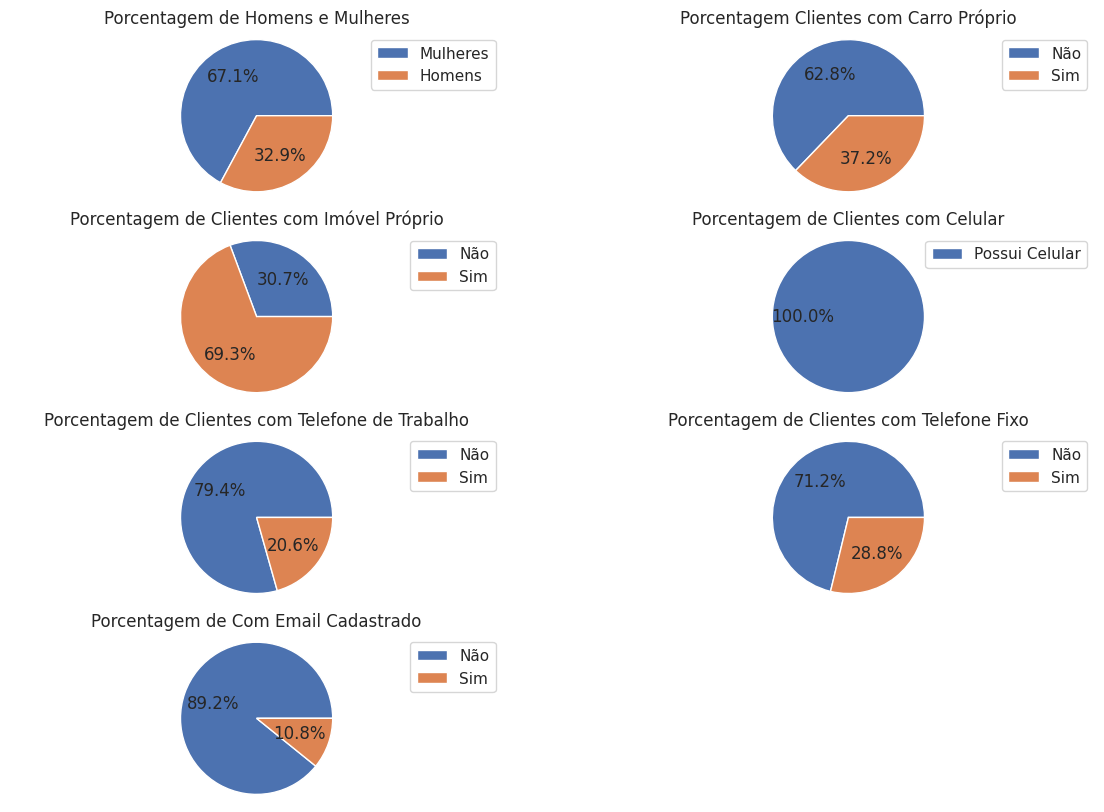

In [14]:
# ============================================
# ANÁLISE: Perfil Demográfico e Conectividade
# ============================================
# Objetivo: Visualizar a distribuição de gênero, bens e canais de contato
# Método: Gráficos de pizza para variáveis categóricas binárias
# Resultado esperado: Predomínio de mulheres, maioria com imóvel, baixa conectividade digital
# ============================================

fig, ax = plt.subplots(4, 2, figsize=(14, 10))

# Gênero
df_genero = df_app.groupby("CODE_GENDER")["ID"].count()
total = df_app.shape[0]
df_porcentagem = df_genero / total * 100
labels = df_porcentagem.index.tolist()
sizes = df_porcentagem.values.tolist()
ax[0,0].pie(sizes, autopct="%1.1f%%")
ax[0,0].axis("equal")
ax[0,0].set_title("Porcentagem de Homens e Mulheres")
ax[0,0].legend(labels=["Mulheres", "Homens"], loc="best")

# Carro próprio
df_genero = df_app.groupby("FLAG_OWN_CAR")["ID"].count()
total = df_app.shape[0]
df_porcentagem = df_genero / total * 100
labels = df_porcentagem.index.tolist()
sizes = df_porcentagem.values.tolist()
ax[0,1].pie(sizes, autopct="%1.1f%%")
ax[0,1].axis("equal")
ax[0,1].set_title("Porcentagem Clientes com Carro Próprio")
ax[0,1].legend(labels=["Não", "Sim"], loc="best")

# Imóvel próprio
df_genero = df_app.groupby("FLAG_OWN_REALTY")["ID"].count()
total = df_app.shape[0]
df_porcentagem = df_genero / total * 100
labels = df_porcentagem.index.tolist()
sizes = df_porcentagem.values.tolist()
ax[1,0].pie(sizes, autopct="%1.1f%%")
ax[1,0].axis("equal")
ax[1,0].set_title("Porcentagem de Clientes com Imóvel Próprio")
ax[1,0].legend(labels=["Não", "Sim"], loc="best")

# Celular
df_genero = df_app.groupby("FLAG_MOBIL")["ID"].count()
total = df_app.shape[0]
df_porcentagem = df_genero / total * 100
labels = df_porcentagem.index.tolist()
sizes = df_porcentagem.values.tolist()
ax[1,1].pie(sizes, autopct="%1.1f%%")
ax[1,1].axis("equal")
ax[1,1].set_title("Porcentagem de Clientes com Celular")
ax[1,1].legend(labels=["Possui Celular"], loc="best")

# Telefone de trabalho
df_genero = df_app.groupby("FLAG_WORK_PHONE")["ID"].count()
total = df_app.shape[0]
df_porcentagem = df_genero / total * 100
labels = df_porcentagem.index.tolist()
sizes = df_porcentagem.values.tolist()
ax[2,0].pie(sizes, autopct="%1.1f%%")
ax[2,0].axis("equal")
ax[2,0].set_title("Porcentagem de Clientes com Telefone de Trabalho")
ax[2,0].legend(labels=["Não", "Sim"], loc="best")

# Telefone fixo
df_genero = df_app.groupby("FLAG_PHONE")["ID"].count()
total = df_app.shape[0]
df_porcentagem = df_genero / total * 100
labels = df_porcentagem.index.tolist()
sizes = df_porcentagem.values.tolist()
ax[2,1].pie(sizes, autopct="%1.1f%%")
ax[2,1].axis("equal")
ax[2,1].set_title("Porcentagem de Clientes com Telefone Fixo")
ax[2,1].legend(labels=["Não", "Sim"], loc="best")

# E-mail
df_genero = df_app.groupby("FLAG_EMAIL")["ID"].count()
total = df_app.shape[0]
df_porcentagem = df_genero / total * 100
labels = df_porcentagem.index.tolist()
sizes = df_porcentagem.values.tolist()
ax[3,0].pie(sizes, autopct="%1.1f%%")
ax[3,0].axis("equal")
ax[3,0].set_title("Porcentagem de Com Email Cadastrado")
ax[3,0].legend(labels=["Não", "Sim"], loc="best")

ax[3,1].axis("off")
plt.show()

**Interpretação:**

**1. Perfil Demográfico e Estabilidade Financeira:**
- **Gênero:** Predomínio expressivo de mulheres (67,1%) contra 32,9% de homens. Pode indicar o público-alvo prioritário da instituição ou um viés de amostragem da carteira.
- **Posse de Bens:** Ampla maioria possui imóvel próprio (69,3%), mas a maior parte não possui veículo (62,8%). A alta taxa de habitação própria sinaliza menor risco de crédito (estabilidade patrimonial), enquanto a baixa motorização pode refletir menor renda discricionária ou perfis de mobilidade urbana concentrada.

**2. Conectividade e Canais de Comunicação:**
- **Celular:** Presente em 100% dos clientes (variância nula), não oferecendo poder preditivo para separar bons e maus pagadores.
- **Baixa penetração de telefone residencial (28,8%) e comercial (20,6%)**, sugerindo perfis com atuação autônoma, informalidade ou menor faixa de renda.
- **Inclusão Digital Baixa:** Apenas 10,8% dos clientes possuem e-mail cadastrado, indicando canais de comunicação predominantemente analógicos ou via mensageria móvel direta.

### 2.2 Dataset ***credit_record.csv***

#### 2.2.1 Saldo Mensal

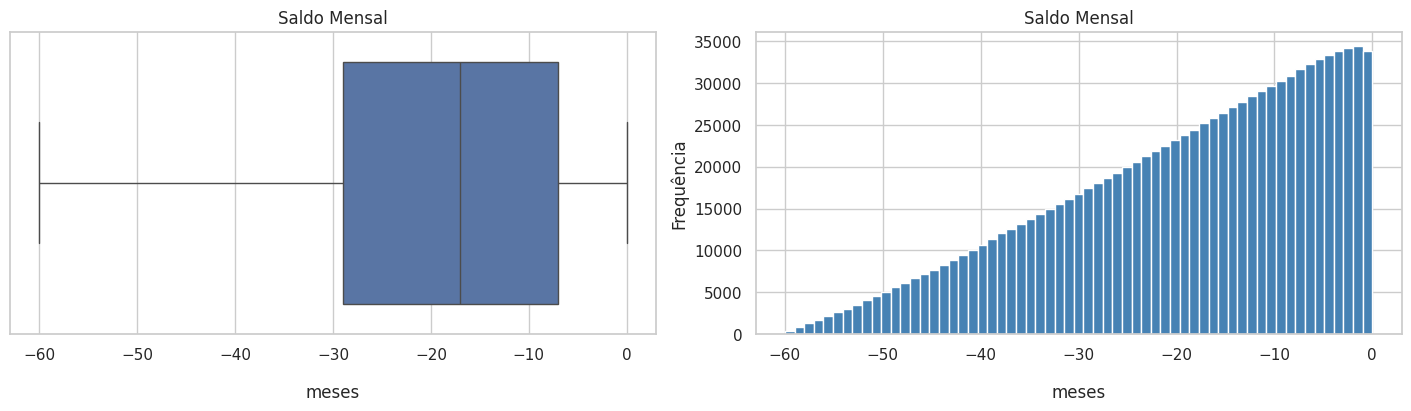

In [15]:
# ============================================
# ANÁLISE: Distribuição do Saldo Mensal
# ============================================
# Objetivo: Verificar a distribuição da variável MONTHS_BALANCE
# Método: Boxplot + Histograma
# Resultado esperado: Distribuição crescente de -60 a 0, sem outliers
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)

sns.boxplot(x="MONTHS_BALANCE", data=df_credit, ax=axes[0])
axes[0].set_xlabel("meses", labelpad=15)
axes[0].set_title("Saldo Mensal")

axes[1].hist(df_credit["MONTHS_BALANCE"], bins=61, color="steelblue", edgecolor="white")
axes[1].set_xlabel("meses", labelpad=15)
axes[1].set_ylabel("Frequência")
axes[1].set_title("Saldo Mensal")
plt.show()

**Interpretação:**

**Boxplot (Distribuição e Amplitude):** A caixa interquartil (IQR) é ampla, situada entre -29 e -7, com mediana em torno de -17 e formato relativamente equilibrado. Não há outliers: os limites cobrem rigorosamente de -60 a 0 (a totalidade da escala observada), sem valores discrepantes.

**Histograma (Frequência e Padrão Temporal):** Exibe um comportamento crescente de -60 até 0, evidenciando que a densidade de informações se amplia conforme o tempo se aproxima do presente. Apresenta pico expressivo no mês 0 (~35.000 clientes) e volume mínimo no extremo mais distante (-60), confirmando a predominância de registros recentes sobre os mais antigos.

**Padrão Estrutural:** Variável temporal limpa, contínua e previsível, reflexo direto do formato de coleta da base (acompanhamento retroativo de até 5 anos / 60 meses). Sem ruídos ou anomalias severas, é o insumo base para calcular a maturidade da conta, recência de pagamento e janelas de observação comportamental sem necessidade de remoção de extremos.

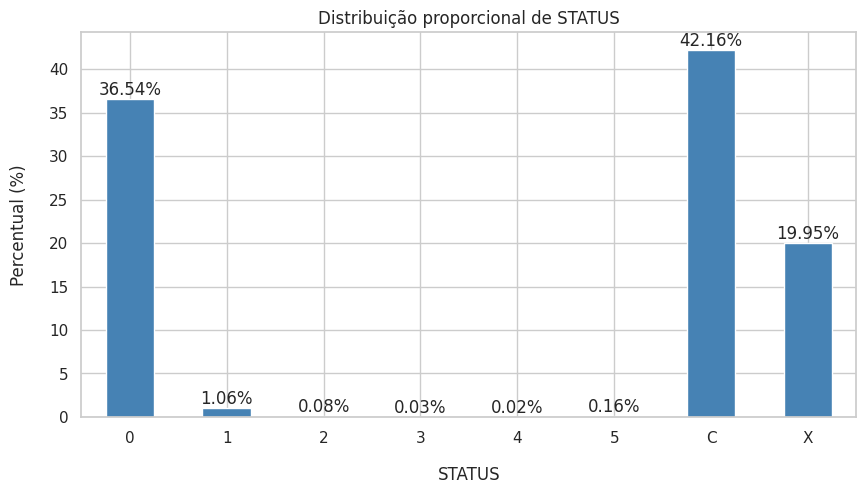

In [16]:
# ============================================
# ANÁLISE: Distribuição Proporcional de STATUS
# ============================================
# Objetivo: Verificar a proporção de cada categoria de STATUS
# Método: value_counts(normalize=True) + gráfico de barras
# Resultado esperado: Concentração massiva em C, 0 e X
# ============================================

prop = df_credit["STATUS"].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(10, 5))
prop.plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
ax.set_xlabel("STATUS", labelpad=15)
ax.set_ylabel("Percentual (%)", labelpad=15)
ax.set_title("Distribuição proporcional de STATUS")
ax.set_xticklabels(prop.index, rotation=0)

for i, v in enumerate(prop):
    ax.text(i, v + 0.5, f"{v:.2f}%", ha="center")
plt.show()

**Interpretação:**

**Categorias Dominantes - Concentração Massiva:** As três principais categorias somam 98,65% de todos os registros da base, indicando que a adimplência ou ausência de dívida ativa é a regra quase absoluta.

**Composição do Top 3:**
- **C (Paid off / Quitado no mês):** 42,16%
- **0 (Atraso leve: 1 a 29 dias):** 36,54%
- **X (Sem empréstimo no mês):** 19,95%

**Cauda Residual (Atrasos Críticos):**
- **Volume Reduzido:** Os atrasos iguais ou superiores a 30 dias representam uma fração residual de apenas 1,35% da base histórica.
- **Distribuição por Gravidade:**
  - 1 (Atraso de 30 a 59 dias): 1,06%
  - 5 (Atraso > 150 dias / Baixa contábil): 0,16%
  - 2 (Atraso de 60 a 89 dias): 0,08%
  - 3 (Atraso de 90 a 119 dias): 0,03%
  - 4 (Atraso de 120 a 149 dias): 0,02%

**Conclusão:** Há um forte desbalanceamento de classes. A esmagadora maioria dos registros representa comportamento saudável (quitado ou atraso leve), enquanto os atrasos graves são raros.

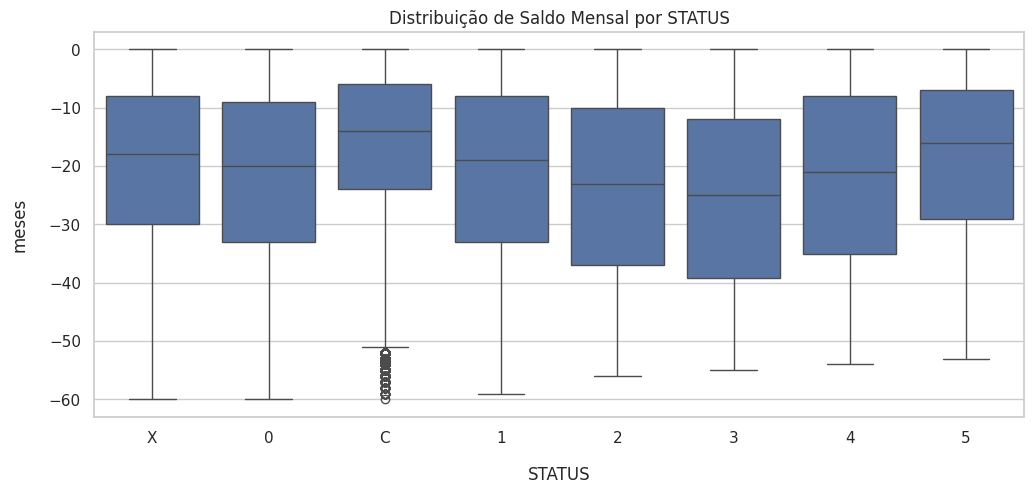

In [17]:
# ============================================
# ANÁLISE: Distribuição de Saldo Mensal por STATUS
# ============================================
# Objetivo: Verificar como cada categoria de STATUS se distribui ao longo do tempo
# Método: Boxplot agrupado por STATUS
# Resultado esperado: C concentrado no presente, atrasos graves no passado
# ============================================

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(x="STATUS", y="MONTHS_BALANCE", data=df_credit, ax=ax)
ax.set_xlabel("STATUS", labelpad=15)
ax.set_ylabel("meses", labelpad=15)
ax.set_title("Distribuição de Saldo Mensal por STATUS")
plt.show()

**Interpretação:**

O Boxplot do Saldo Mensal nos mostra em que momento da linha do tempo (de 0 a -60 meses) cada tipo de situação de pagamento costuma acontecer:

- **Contas Quitadas (C) acontecem mais no presente:** A caixinha do status C é a mais alta e próxima do zero (o mês atual). Isso significa que as contas que foram totalmente pagas e encerradas com sucesso tendem a se concentrar em datas mais recentes.

- **Inadimplências graves (1 a 5) ficam "presas" no passado:** Repare que as caixas de atrasos maiores (como status 3, 4 ou 5) estão posicionadas mais para baixo (períodos mais antigos). Isso ocorre porque uma dívida grave não fica aberta para sempre: depois de alguns meses atrasada, a conta é cancelada, renegociada ou o banco assume o prejuízo. Por isso, esses registros param de andar no tempo e ficam concentrados no passado.

- **Atrasos leves (0) ocorrem o tempo todo:** A caixa do status 0 (atraso de até 29 dias) é grande e espalhada. Isso mostra que esquecer de pagar a fatura por alguns dias é um comportamento comum e que acontece de forma parecida ao longo de todos os 5 anos analisados.

**Conclusão:** O tempo de vida da conta (MONTHS_BALANCE) está diretamente ligado à saúde do crédito (STATUS).

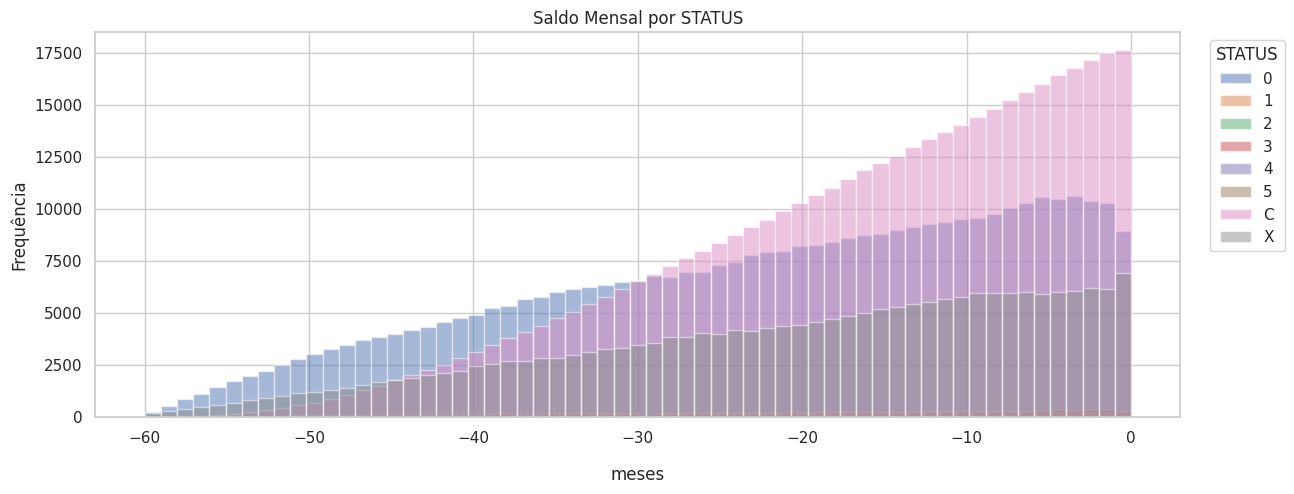

In [18]:
# ============================================
# ANÁLISE: Histograma Empilhado de Saldo Mensal por STATUS
# ============================================
# Objetivo: Verificar a composição de MONTHS_BALANCE por STATUS
# Método: Histograma empilhado com alpha=0.5
# Resultado esperado: C cresce em direção ao presente, 0 é constante
# ============================================

fig, ax = plt.subplots(figsize=(14, 5))
for status in sorted(df_credit["STATUS"].unique()):
    subset = df_credit[df_credit["STATUS"] == status]["MONTHS_BALANCE"]
    ax.hist(subset, bins=61, alpha=0.5, label=status)

ax.set_xlabel("meses", labelpad=15)
ax.set_ylabel("Frequência")
ax.set_title("Saldo Mensal por STATUS")
ax.legend(title="STATUS", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**Interpretação:**

O gráfico mostra a composição de `MONTHS_BALANCE` por `STATUS`, permitindo ver como cada categoria se distribui ao longo dos 60 meses da janela. O padrão geral é de crescimento monotônico: a frequência aumenta de forma contínua de -60 até 0, refletindo o acúmulo natural de registros ao longo do tempo.

A categoria `C` (quitado no mês) é a que mais cresce em direção ao presente: ela domina a parte superior do empilhamento nos meses recentes, especialmente entre -20 e 0. Isso confirma a leitura do boxplot anterior — clientes que quitam tendem a fazê-lo em momentos mais recentes do histórico.

A categoria `0` (atraso leve) tem presença constante ao longo de todo o período, mas proporcionalmente maior nos meses mais antigos (entre -60 e -40). Já `X` (sem empréstimo) aparece como uma faixa inferior estável, presente em todos os meses com volume relativamente constante.

As categorias de atraso grave (`1`, `2`, `3`, `4`, `5`) aparecem como faixas finas e quase invisíveis no empilhamento — reflexo direto do desbalanceamento extremo da base. Apenas `1` (30 a 59 dias) tem alguma expressão visual, concentrada nos meses mais antigos.

**Conclusão:** Esses padrões confirmam que `MONTHS_BALANCE` e `STATUS` não são independentes: o momento temporal do registro carrega informação sobre a situação do crédito.

## 3. Correlações

**Interpretação:** _comente cada correlação relevante, uma a uma._

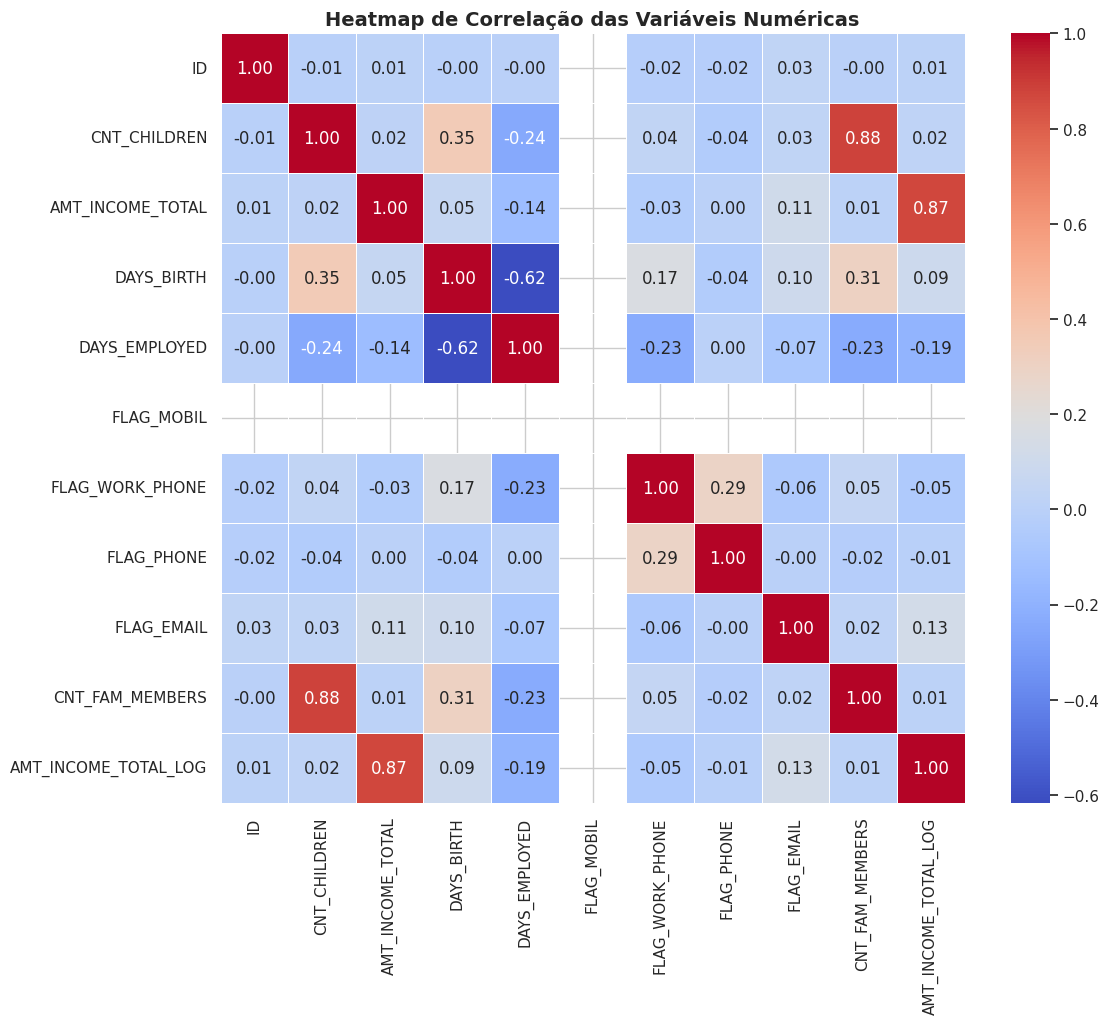

In [19]:
# ============================================
# ANÁLISE: Matriz de Correlação de Pearson
# ============================================
# Objetivo: Verificar correlações lineares entre variáveis numéricas
# Método: df.corr() + sns.heatmap()
# Resultado esperado: Identificar correlações fortes e redundâncias
# ============================================

numeric_cols = df_app.select_dtypes(include=[np.number])
correlation_matrix = numeric_cols.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5)
plt.title("Heatmap de Correlação das Variáveis Numéricas", fontsize=14, fontweight="bold")
plt.show()

**Interpretação:**

> **Observação sobre `DAYS_EMPLOYED`:** Esta variável contém o valor sentinela 365243 para clientes pensionistas/aposentados (que não estão empregados). Esse valor é um placeholder, não um tempo real de emprego (~1000 anos). Enquanto não for tratado, ele distorce severamente as correlações envolvendo essa variável e quaisquer outras que se relacionem com idade ou renda.

**Principais Insights:**

O coeficiente de Pearson varia de -1,00 (relação linear negativa perfeita) a +1,00 (relação linear positiva perfeita), com valores próximos de 0,00 indicando ausência de associação linear.

- **CNT_CHILDREN × CNT_FAM_MEMBERS: 0,88** — Forte correlação positiva direta. O volume de filhos compõe diretamente o tamanho total do núcleo familiar. Indica redundância informacional e risco de multicolinearidade. Em modelos lineares (como Regressão Logística), infla a variância dos estimadores e desestabiliza os coeficientes.

- **DAYS_BIRTH × DAYS_EMPLOYED: -0,62** — Aparente associação moderada a forte que não reflete a realidade do fenômeno. Causa do Viés: Clientes mais velhos (aposentados/pensionistas) receberam arbitrariamente o código 365.243 na coluna de emprego. Esse ponto extremo alavanca e distorce o cálculo matemático. Ao isolar o sentinela, a correlação real entre idade e tempo de serviço cai expressivamente.

- **CNT_CHILDREN × DAYS_BIRTH: 0,35** — Associação moderada válida. Como a idade é registrada em dias retroativos (valores negativos), números menos negativos representam indivíduos mais jovens. Sinaliza uma dinâmica demográfica plausível: clientes em faixas etárias mais jovens no cadastro concentram maior número de filhos e dependentes ativos.

- **FLAG_MOBIL (Variância Zero):** Como 100% da base possui celular, o desvio padrão é nulo, impossibilitando o cálculo da correlação (divisão por zero).

- **AMT_INCOME_TOTAL (Independência Financeira):** Coeficientes próximos de zero com as demais features, indicando que a renda anual atua de forma ortogonal (independente) em relação aos atributos demográficos dos clientes.

## 4. Outliers

**Interpretação:** _remover, winsorizar ou manter? Justifique._

In [20]:
# ============================================
# ANÁLISE: Detecção de Outliers via IQR
# ============================================
# Objetivo: Identificar outliers estatísticos nas variáveis numéricas
# Método: Intervalo Interquartil (IQR) com multiplicador 1.5
# Resultado esperado: Quantificar outliers em cada variável
# ============================================

def detect_outliers_iqr(df, column):
    """Detecta outliers usando o método IQR (Intervalo Interquartil)."""
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    outliers = df[(df[column] < limite_inferior) | (df[column] > limite_superior)]
    return len(outliers), limite_inferior, limite_superior

for col in ["AMT_INCOME_TOTAL", "DAYS_EMPLOYED", "CNT_CHILDREN", "CNT_FAM_MEMBERS"]:
    n_outliers, li, ls = detect_outliers_iqr(df_app, col)
    print(f"{col}: {n_outliers} outliers | Limite inferior: {li:.2f} | Limite superior: {ls:.2f}")

AMT_INCOME_TOTAL: 19108 outliers | Limite inferior: -33750.00 | Limite superior: 380250.00
DAYS_EMPLOYED: 97300 outliers | Limite inferior: -7201.00 | Limite superior: 3727.00
CNT_CHILDREN: 6075 outliers | Limite inferior: -1.50 | Limite superior: 2.50
CNT_FAM_MEMBERS: 5690 outliers | Limite inferior: 0.50 | Limite superior: 4.50


**Interpretação:**

**Decisão: manter, mas tratar**

A aplicação do método IQR aponta uma quantidade expressiva de valores discrepantes, sobretudo em `AMT_INCOME_TOTAL` (19.108) e `DAYS_EMPLOYED` (97.300). No entanto, a decisão de tratamento difere por variável:

- **`AMT_INCOME_TOTAL`:** os outliers são rendas altas legítimas, que refletem a disparidade econômica real dos solicitantes. Optou-se por manter os registros para preservar a capacidade de generalização do modelo, aplicando log-transform na etapa de modelagem para reduzir a assimetria.

- **`DAYS_EMPLOYED`:** os 97.300 "outliers" não são valores legítimos — são o valor sentinela 365243, que representa clientes sem emprego formal - no nosso dataset pensionista. Optou-se por substituir por `NaN` e criar a flag is_unemployed.

- **`CNT_CHILDREN` e `CNT_FAM_MEMBERS`:** os outliers (19 filhos, 20 membros) podem ser casos reais ou erros de cadastro. Optou-se por manter os registros, mas recomenda-se inspeção manual e binarização (`0`, `1`, `2`, `3-5`, `6+`) na etapa de modelagem para reduzir o efeito dos extremos.

Em todos os casos, a premissa é a mesma: outliers em dados de crédito raramente são erros — mas nem todos são sinal. O tratamento deve ser variável a variável, e não uma regra única aplicada cegamente.

## 5. Balanceamento de classes

**Interpretação:** _qual a proporção entre as classes e o que isso implica na escolha das métricas?_

In [21]:
# ============================================
# ANÁLISE: Balanceamento de Classes
# ============================================
# Objetivo: Verificar a proporção entre classes (Bom vs Mau Pagador)
# Método: Binarização do STATUS + groupby + value_counts(normalize=True)
# Resultado esperado: Desbalanceamento severo (~98% vs ~2%)
# ============================================

# Binarização: atraso >= 60 dias (status 2, 3, 4, 5) -> 1 (Mau Pagador)
def rotular_inadimplencia(status):
    if status in ["2", "3", "4", "5", 2, 3, 4, 5]:
        return 1  # Mau Pagador
    return 0      # Bom Pagador

df_credit["eh_mau_pagador"] = df_credit["STATUS"].apply(rotular_inadimplencia)
df_target = df_credit.groupby("ID")["eh_mau_pagador"].max().reset_index()

print("Distribuição do target:")
print(df_target["eh_mau_pagador"].value_counts(normalize=True))

Distribuição do target:
eh_mau_pagador
0    0.985495
1    0.014505
Name: proportion, dtype: float64


**Interpretação:**

**Definição Estratégica da Variável-Alvo (eh_mau_pagador)**

Objetivo: Traduzir a complexidade de uma série temporal multivariada (credit_record) em uma classificação binária objetiva (0 = Bom Pagador, 1 = Mau Pagador), estabelecendo a fronteira matemática que orienta todo o treinamento do modelo.

**1. Racional do Limite de 60 Dias (Status 2 a 5):**
- **Atrasos Curtos (Status 0 e 1 / até 59 dias):** Representam oscilações temporárias de fluxo de caixa, esquecimento ou descasamento de datas. Possuem altíssima taxa de regularização voluntária (auto-cura), não configurando perda efetiva para o credor.
- **Atrasos Severos (Status 2 a 5 / ≥ 60 dias):** Ponto de inflexão estatístico em que a probabilidade de recuperação despenca e a chance de calote definitivo (write-off) cresce exponencialmente. No padrão de risco bancário, 60 dias de atraso marcam a transição de um problema de liquidez passageiro para uma insolvência estrutural.

**2. Racional da Agregação por .max():**
- **Princípio Conservador de Risco:** Consolida o cliente pelo seu pior momento histórico. Mesmo que o solicitante tenha sido pontual em dezenas de meses, um único registro atingindo ≥ 60 dias basta para rotulá-lo como Mau Pagador (1).
- **Força o modelo de Machine Learning a identificar características cadastrais associadas à fragilidade sob estresse financeiro, impedindo que um histórico predominantemente adimplente mascare a incapacidade de honrar compromissos em cenários de crise.**

## 6. Síntese da EDA

_Amarre os achados em uma narrativa única — é ela que vira o storytelling da apresentação._

**1. O Perfil do Cliente: Quem pede crédito?**

- **Estabilidade e Família Pequena:** A maioria dos clientes são mulheres (67,1%), em plena idade produtiva (cerca de 43 anos) e com lares pequenos — geralmente duas pessoas e sem filhos. Cerca de 70% têm casa própria (ótimo sinal de estabilidade), mas 63% não têm carro.
- **Contato Direto:** Todos têm celular cadastrado (100%), mas quase ninguém usa e-mail (só 10,8%), mostrando que a comunicação precisa ser via telefone ou mensagens diretas.

**2. Armadilhas Técnicas: O que tivemos que corrigir?**

- **O "Emprego de Mil Anos":** Cerca de 17% da base aparecia com 365.243 dias trabalhados. Isso era apenas um código do sistema para identificar aposentados e desempregados; Na prática, quem trabalha tem vínculos relativamente novos (entre 2 e 5 anos).
- **Salários Discrepantes:** A renda média é puxada para cima por poucos clientes milionários.

**3. Comportamento Histórico: Como eles pagam as contas?**

- **A esmagadora maioria paga em dia:** Em quase todos meses analisados, as faturas estavam totalmente quitadas ou com atrasos leves de menos de 30 dias.
- **Contratos saudáveis continuam ativos até o presente, enquanto os calotes pesados aparecem concentrados no passado — porque o banco corta o crédito, renegocia ou dá a dívida como perdida.**

**4. A Regra do Risco: Quem consideramos "Mau Pagador"?**

- **A Linha dos 60 Dias:** Atrasar até 59 dias muitas vezes é mero esquecimento ou aperto passageiro, e o cliente acaba pagando. A partir de 60 dias de atraso, o calote definitivo se torna quase certo.
- **Critério Conservador:** Se o cliente teve um atraso de 60 dias ou mais em qualquer mês ao longo dos últimos 5 anos, ele é marcado como cliente de risco.

**5. O Desafio do Modelo: A "Agulha no Palheiro"**

- **Desbalanceamento Extremo:** Apenas 1,7% da base é de maus pagadores, contra 98,3% de bons pagadores.
- **A Armadilha da Acurácia:** Se o modelo simplesmente disser "sim" para todo mundo, ele vai acertar 98% das vezes na matemática, mas vai quebrar o banco ao deixar todos os caloteiros entrarem.
- **O algoritmo não deve ser julgado por acertos gerais, mas pela capacidade de encontrar esses 1,7% de risco.**